# 02 · Árboles de decisión y ensambles

**Objetivo:** ver un árbol pasar de subajuste a sobreajuste con la profundidad, y por qué
promediar muchos árboles (bagging, random forest) o sumarlos en secuencia (boosting) arregla
problemas distintos: **varianza** el primero, **sesgo** el segundo.

Todos los modelos de este notebook son los de `applied_ml`, implementados desde cero.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_ml import DecisionTreeClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.datasets import make_classification, make_moons
from sklearn.ensemble import GradientBoostingClassifier as SkGB
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

X, y = make_moons(600, noise=0.3, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, random_state=0)

## 1. Profundidad: de subajuste a sobreajuste

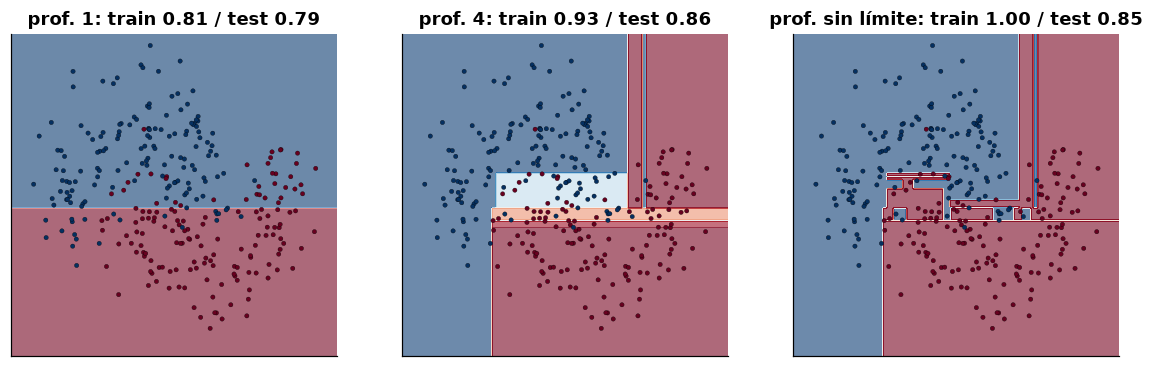

In [2]:
gx, gy = np.meshgrid(np.linspace(-1.8, 2.8, 250), np.linspace(-1.3, 1.8, 250))
grid = np.c_[gx.ravel(), gy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, depth in zip(axes, [1, 4, None], strict=True):
    t = DecisionTreeClassifier(max_depth=depth).fit(Xtr, ytr)
    proba = t.predict_proba(grid)[:, 1].reshape(gx.shape)
    ax.contourf(gx, gy, proba, levels=20, cmap="RdBu_r", alpha=0.6)
    ax.scatter(*Xtr.T, c=ytr, cmap="RdBu_r", s=8, edgecolor="k", lw=0.2)
    label = depth or "sin límite"
    ax.set_title(f"prof. {label}: train {t.score(Xtr, ytr):.2f} / test {t.score(Xte, yte):.2f}")
    ax.set_xticks([])
    ax.set_yticks([])

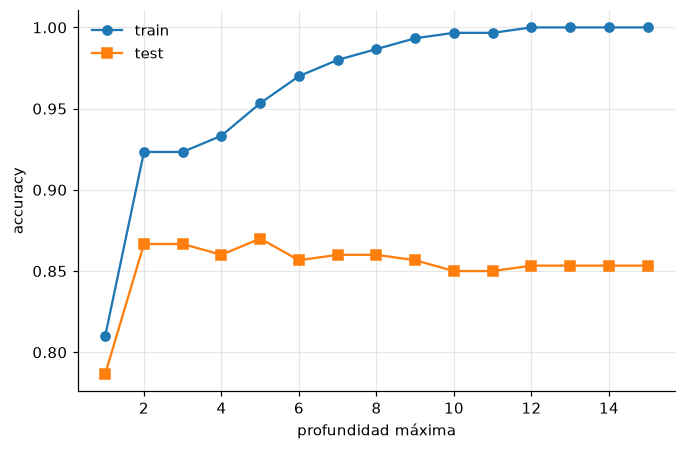

In [3]:
depths = range(1, 16)
train_acc = [DecisionTreeClassifier(max_depth=d).fit(Xtr, ytr).score(Xtr, ytr) for d in depths]
test_acc = [DecisionTreeClassifier(max_depth=d).fit(Xtr, ytr).score(Xte, yte) for d in depths]
fig, ax = plt.subplots()
ax.plot(depths, train_acc, "o-", label="train")
ax.plot(depths, test_acc, "s-", label="test")
ax.set_xlabel("profundidad máxima")
ax.set_ylabel("accuracy")
ax.legend();

## 2. Los árboles profundos tienen varianza alta

Entrenamos 50 árboles en remuestras bootstrap distintas y miramos cuánto cambian sus predicciones
en los mismos puntos. Luego, la correlación entre árboles con y sin submuestreo de features
(`max_features`): es lo que limita cuánto ayuda promediar, porque
$\text{Var}(\bar T) = \rho\sigma^2 + (1-\rho)\sigma^2/B$.

In [4]:
Xc, yc = make_classification(1500, n_features=20, n_informative=6, random_state=1)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.5, random_state=1)


def tree_predictions(max_features, B=40):
    preds = []
    for b in range(B):
        idx = rng.integers(0, len(Xc_tr), len(Xc_tr))
        t = DecisionTreeClassifier(max_features=max_features, random_state=b).fit(
            Xc_tr[idx], yc_tr[idx]
        )
        preds.append(t.predict_proba(Xc_te)[:, 1])
    return np.array(preds)


for mf in [None, "sqrt"]:
    P = tree_predictions(mf)
    corr = np.corrcoef(P)[np.triu_indices(len(P), 1)].mean()
    single = np.mean([roc_auc_score(yc_te, p) for p in P])
    avg = roc_auc_score(yc_te, P.mean(0))
    print(
        f"max_features={mf!s:<5} ρ medio = {corr:.3f} | AUC de un árbol = {single:.3f}"
        f" | AUC del promedio de {len(P)} = {avg:.3f}"
    )

max_features=None  ρ medio = 0.587 | AUC de un árbol = 0.805 | AUC del promedio de 40 = 0.936


max_features=sqrt  ρ medio = 0.488 | AUC de un árbol = 0.782 | AUC del promedio de 40 = 0.943


Con `max_features="sqrt"` cada árbol individual es *peor*, pero son menos parecidos entre sí,
y el promedio resulta mejor: es la idea central del random forest.

### OOB: validación gratis

In [5]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=0).fit(Xc_tr, yc_tr)
print(f"accuracy OOB = {rf.oob_score_:.3f} | accuracy en test = {rf.score(Xc_te, yc_te):.3f}")

accuracy OOB = 0.881 | accuracy en test = 0.885


## 3. Boosting: corregir el sesgo de árboles débiles

Cada árbol (profundidad 2) se ajusta al error del ensamble anterior. La tasa de aprendizaje
controla cuánto se avanza: tasas altas sobreajustan antes.

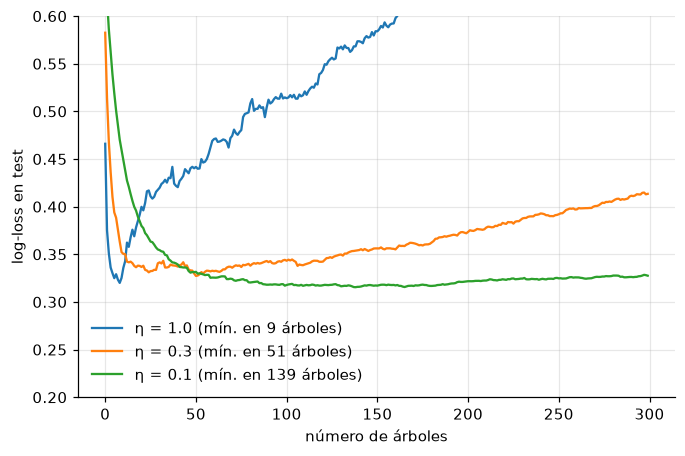

In [6]:
fig, ax = plt.subplots()
for lr in [1.0, 0.3, 0.1]:
    gb = GradientBoostingClassifier(n_estimators=300, learning_rate=lr, max_depth=2).fit(
        Xc_tr, yc_tr
    )
    test_loss = [
        np.mean(np.logaddexp(0, f) - yc_te * f) for f in gb.staged_decision_function(Xc_te)
    ]
    ax.plot(test_loss, label=f"η = {lr} (mín. en {int(np.argmin(test_loss)) + 1} árboles)")
ax.set_xlabel("número de árboles")
ax.set_ylabel("log-loss en test")
ax.set_ylim(0.2, 0.6)
ax.legend();

In [7]:
ours = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=2).fit(
    Xc_tr, yc_tr
)
ref = SkGB(n_estimators=150, learning_rate=0.1, max_depth=2, random_state=0).fit(Xc_tr, yc_tr)
print(f"AUC desde cero = {roc_auc_score(yc_te, ours.predict_proba(Xc_te)[:, 1]):.4f}")
print(f"AUC sklearn    = {roc_auc_score(yc_te, ref.predict_proba(Xc_te)[:, 1]):.4f}")

AUC desde cero = 0.9379
AUC sklearn    = 0.9383


## Para llevar

- Un árbol profundo tiene sesgo bajo y varianza alta; uno poco profundo, al revés.
- Bagging/RF reducen varianza promediando árboles **decorrelacionados**; el OOB estima el error sin CV.
- Boosting reduce sesgo sumando árboles débiles; *learning rate* bajo + más árboles generaliza mejor.
- En datos tabulares, gradient boosting (HistGradientBoosting, XGBoost, LightGBM) suele ganar:
  así fue en el proyecto.